In [15]:
import pandas as pd
import numpy as np
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install scikit-learn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
df = pd.read_csv("../data/study_sessions.csv")

In [2]:
df.head()

,sleep_hours,study_hours,break_minutes,phone_hours,stress_level,caffeine,previous_productivity,productivity
0,5.9,4.3,51,1.0,1,3,64,Medium
1,8.8,3.4,16,5.0,7,1,35,Low
2,7.7,2.2,20,2.5,8,0,97,Low
3,7.0,5.0,28,2.3,3,2,47,Medium
4,4.8,4.3,23,5.9,5,1,58,Low


In [4]:
X = df.drop("productivity", axis=1)
y = df["productivity"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [6]:
import joblib

model = joblib.load("../src/study_mood_model.pkl")

In [7]:
y_pred = model.predict(X_test)

In [17]:
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [13]:
accuracy_score(y_test, y_pred)
precision_score(y_test, y_pred, average="weighted")
recall_score(y_test, y_pred, average="weighted")
f1_score(y_test, y_pred, average="weighted")
print(classification_report(y_test, y_pred))

d:\study-mood-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

        High       0.00      0.00      0.00         1
         Low       0.87      0.97      0.92        69
      Medium       0.87      0.67      0.75        30

    accuracy                           0.87       100
   macro avg       0.58      0.55      0.56       100
weighted avg       0.86      0.87      0.86       100



d:\study-mood-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\study-mood-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\study-mood-ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


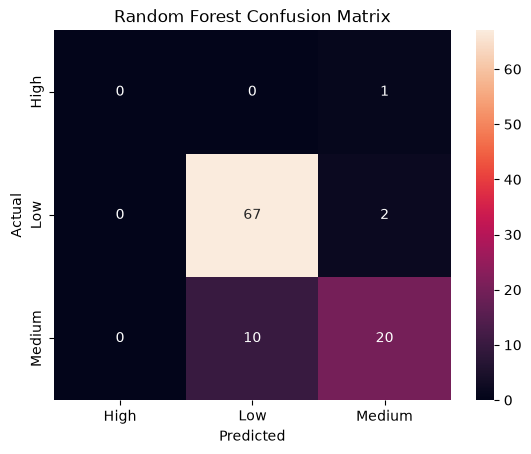

In [18]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [19]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

d:\study-mood-ai\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
